Loading cleaned dataset...
Total Dataset Rows: 525600
Input Features: ['T1_O2', 'T1_NH4', 'T1_PO4', 'TEMPERATURE', 'IN_Q', 'IN_METAL_Q', 'METAL_Q', 'MAX_CF']
Target Variables: ['T1_O2', 'T1_NH4', 'T1_PO4']
Training Samples (80%): 420480
Testing Samples (20%): 105120
Generating training sequences...
Generating testing sequences...
TCN Training Sequence Shape: (420420, 60, 8)
TCN Testing Sequence Shape: (105120, 60, 8)

Building TCN model architecture...


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 60, 64)         │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 60, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,467 (103.39 KB)

 Trainable params: 26,467 (103.39 KB)

 Non-trainable params: 0 (0.00 B)


Training TCN model...
Epoch 1/15
5913/5913 ━━━━━━━━━━━━━━━━━━━━ 171s 28ms/step - loss: 8.2695e-04 - mae: 0.0183 - val_loss: 4.2088e-04 - val_mae: 0.0146
Epoch 2/15
5913/5913 ━━━━━━━━━━━━━━━━━━━━ 142s 24ms/step - loss: 5.3961e-04 - mae: 0.0150 - val_loss: 2.2942e-04 - val_mae: 0.0095
Epoch 3/15
5913/5913 ━━━━━━━━━━━━━━━━━━━━ 145s 25ms/step - loss: 5.1119e-04 - mae: 0.0145 - val_loss: 2.1159e-04 - val_mae: 0.0089
Epoch 4/15
5913/5913 ━━━━━━━━━━━━━━━━━━━━ 143s 24ms/step - loss: 4.9879e-04 - mae: 0.0143 - val_loss: 2.0343e-04 - val_mae: 0.0089
Epoch 5/15
5913/5913 ━━━━━━━━━━━━━━━━━━━━ 141s 24ms/step - loss: 4.8589e-04 - mae: 0.0141 - val_loss: 1.9222e-04 - val_mae: 0.0085
Epoch 6/15
5913/5913 ━━━━━━━━━━━━━━━━━━━━ 154s 26ms/step - loss: 4.8422e-04 - mae: 0.0140 - val_loss: 2.2847e-04 - val_mae: 0.0093
Epoch 7/15
5913/5913 ━━━━━━━━━━━━━━━━━━━━ 142s 24ms/step - loss: 4.7506e-04 - mae: 0.0139 - val_loss: 1.8935e-04 - val_mae: 0.0079
Epoch 8/15
5913/5913 ━━━━━━━━━━━━━━━━━━━━ 142s 24ms/step - l

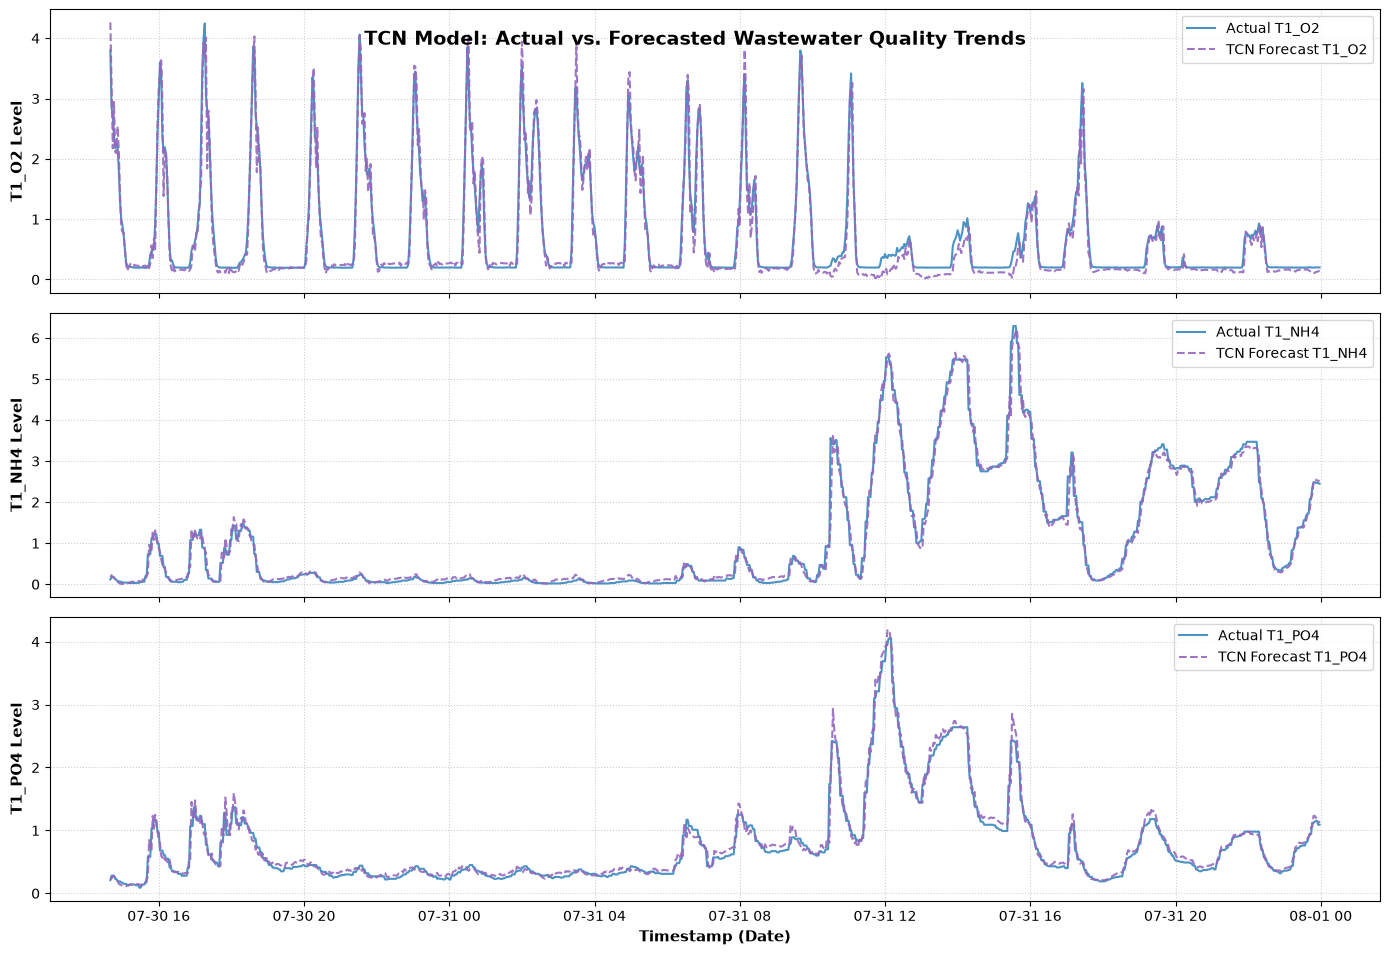

✓ TCN Visualization completed and displayed successfully!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -------------------------------------------------------------------------
# Step 1: Load and Prepare the Cleaned Dataset
# -------------------------------------------------------------------------
print("Loading cleaned dataset...")
df = pd.read_csv('wastewater_model_Cleaned data.csv')

# Ensure chronological sorting
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Define target variables and input features
target_columns = ['T1_O2', 'T1_NH4', 'T1_PO4']
feature_cols = [c for c in df.columns if c != 'date']

print(f"Total Dataset Rows: {len(df)}")
print("Input Features:", feature_cols)
print("Target Variables:", target_columns)

# -------------------------------------------------------------------------
# Step 2: Chronological Train-Test Split (80% Train, 20% Test)
# -------------------------------------------------------------------------
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy().reset_index(drop=True)

print(f"Training Samples (80%): {len(train_df)}")
print(f"Testing Samples (20%): {len(test_df)}")

# -------------------------------------------------------------------------
# Step 3: Feature Scaling & Optimized Sliding Window Sequence Creation
# -------------------------------------------------------------------------
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

X_train_scaled = feature_scaler.fit_transform(train_df[feature_cols]).astype(np.float32)
X_test_scaled = feature_scaler.transform(test_df[feature_cols]).astype(np.float32)

y_train_scaled = target_scaler.fit_transform(train_df[target_columns]).astype(np.float32)
y_test_scaled = target_scaler.transform(test_df[target_columns]).astype(np.float32)

WINDOW_SIZE = 60

def create_sequences_optimized(X, y, window_size):
    num_samples = len(X) - window_size
    Xs = np.empty((num_samples, window_size, X.shape[1]), dtype=np.float32)
    ys = np.empty((num_samples, y.shape[1]), dtype=np.float32)
    for i in range(num_samples):
        Xs[i] = X[i : i + window_size]
        ys[i] = y[i + window_size]
    return Xs, ys

print("Generating training sequences...")
X_train_seq, y_train_seq = create_sequences_optimized(X_train_scaled, y_train_scaled, WINDOW_SIZE)

print("Generating testing sequences...")
X_test_with_history = np.concatenate([X_train_scaled[-WINDOW_SIZE:], X_test_scaled], axis=0)
y_test_with_history = np.concatenate([y_train_scaled[-WINDOW_SIZE:], y_test_scaled], axis=0)
X_test_seq, y_test_seq = create_sequences_optimized(X_test_with_history, y_test_with_history, WINDOW_SIZE)

print(f"TCN Training Sequence Shape: {X_train_seq.shape}")
print(f"TCN Testing Sequence Shape: {X_test_seq.shape}")

# -------------------------------------------------------------------------
# Step 4: Build and Train the TCN (or Hybrid TCN-LSTM) Model Architecture
# -------------------------------------------------------------------------
print("\nBuilding TCN model architecture...")
input_shape = (X_train_seq.shape[1], X_train_seq.shape[2])

# Temporal Convolutional Network (TCN) structure with Causal Dilated Convolutions
tcn_model = Sequential([
    Input(shape=input_shape),
    Conv1D(filters=64, kernel_size=3, padding='causal', dilation_rate=1, activation='relu'),
    Dropout(0.1),
    Conv1D(filters=64, kernel_size=3, padding='causal', dilation_rate=2, activation='relu'),
    Dropout(0.1),
    LSTM(32, return_sequences=False), # Optional LSTM layer to combine TCN feature extraction with RNN memory[cite: 3]
    Dropout(0.2),
    Dense(len(target_columns))         # Simultaneously predicts T1_O2, T1_NH4, and T1_PO4
])

tcn_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
tcn_model.summary()

print("\nTraining TCN model...")
history = tcn_model.fit(
    X_train_seq, y_train_seq,
    epochs=15,          # Adjust epochs as needed (e.g., 20-30 for full convergence)
    batch_size=64,
    validation_split=0.1,
    verbose=1
)
print("✓ TCN model training completed successfully!")

# -------------------------------------------------------------------------
# Step 5: Generate Predictions & Inverse Transform to Original Units
# -------------------------------------------------------------------------
y_pred_scaled = tcn_model.predict(X_test_seq, batch_size=64)

# Inverse transform back to original physical units (mg/L)
y_pred_inv = target_scaler.inverse_transform(y_pred_scaled)
y_test_inv = target_scaler.inverse_transform(y_test_seq)

# -------------------------------------------------------------------------
# Step 6: Calculate Evaluation Metrics & Percentage Accuracy
# -------------------------------------------------------------------------
tcn_results = []
for i, col in enumerate(target_columns):
    actual = y_test_inv[:, i]
    pred = y_pred_inv[:, i]
    
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    r2 = r2_score(actual, pred)
    
    # Accuracy metric 1: Within ±10% operational tolerance window
    tolerance = 0.10 * np.abs(actual)
    accurate_preds = np.abs(actual - pred) <= tolerance
    accuracy_tolerance_pct = (np.sum(accurate_preds) / len(actual)) * 100
    
    # Accuracy metric 2: Overall percentage accuracy based on MAPE (100 - MAPE)
    mape = np.mean(np.abs((actual - pred) / (np.abs(actual) + 1e-8))) * 100
    overall_accuracy_pct = max(0, 100 - mape)
    
    tcn_results.append({
        "Model": "TCN Model",
        "Target Variable": col,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R² Score": round(r2, 4),
        "Accuracy (±10% Window)": f"{round(accuracy_tolerance_pct, 2)}%",
        "Overall Accuracy (100-MAPE)": f"{round(overall_accuracy_pct, 2)}%"
    })

tcn_eval_df = pd.DataFrame(tcn_results)
print("\n--- TCN Model Evaluation & Accuracy Results ---")
print(tcn_eval_df.to_string(index=False))

# -------------------------------------------------------------------------
# Step 7: Data Visualization (Actual vs. TCN Forecast Visualization)
# -------------------------------------------------------------------------
print("\nGenerating visualization plots...")
test_dates = test_df['date'].iloc[:len(y_test_inv)].reset_index(drop=True)
subset_steps = 1000  # Plot last 1,000 observations for high visual clarity

fig, axes = plt.subplots(len(target_columns), 1, figsize=(14, 10), sharex=True)

for i, col in enumerate(target_columns):
    axes[i].plot(
        test_dates.iloc[-subset_steps:], 
        y_test_inv[-subset_steps:, i], 
        label=f'Actual {col}', 
        color='#1f77b4', 
        alpha=0.8, 
        linewidth=1.5
    )
    axes[i].plot(
        test_dates.iloc[-subset_steps:], 
        y_pred_inv[-subset_steps:, i], 
        label=f'TCN Forecast {col}', 
        color='#9467bd', 
        linestyle='--', 
        alpha=0.9, 
        linewidth=1.5
    )
    axes[i].set_ylabel(f'{col} Level', fontsize=11, fontweight='bold')
    axes[i].legend(loc='upper right', frameon=True)
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('TCN Model: Actual vs. Forecasted Wastewater Quality Trends', fontsize=14, fontweight='bold', y=0.93)
plt.xlabel('Timestamp (Date)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()
print("✓ TCN Visualization completed and displayed successfully!")

In [3]:
import joblib

tcn_model.save("tcn_wastewater_model.keras")
# Save preprocessing scalers
joblib.dump(feature_scaler, "feature_scaler.pkl")
joblib.dump(target_scaler, "target_scaler.pkl")

print("✓ LSTM, TCN models and scalers successfully saved for Streamlit!")


✓ LSTM, TCN models and scalers successfully saved for Streamlit!
